<a href="https://colab.research.google.com/github/AdityaSAdhikari/LINDEF-Lightweight-Real-Time-Network-Intrusion-Detection-and-Containment-Framework/blob/main/Final_Runs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final runs: synthetic stage

Produces the paper's tables and figure for Propositions 1–3, with longer paths (5,000 days), more paths (2,000), and two random seeds.

- **Your functions are copied unchanged** from `Generators.ipynb`.
- The only addition is **faster versions** of the three loop functions (`apply_stop_loss`, `generate_ar1`, `generate_RS`), using Numba. Section 2 checks they give the same results as your originals before anything else runs.
- Everything is saved to `Stop Loss Paper/final/` in Drive.

Run with **Runtime → Run all** on a CPU runtime. Expect roughly 15–25 minutes in total.

## 0. Setup

In [ ]:
import numpy as np
import pandas as pd
import time, os
from numba import njit
from google.colab import drive
drive.mount('/content/drive')

OUT = '/content/drive/MyDrive/Stop Loss Paper/final'
os.makedirs(OUT, exist_ok=True)

# Simulation size for the paper
N_PATHS = 2000
N_STEPS = 5000
SEEDS   = [42, 7]          # two seeds: results should agree within noise

# Market: random walk / AR(1)
mu_ann, sigma_ann, rf_ann, dt = 0.08, 0.18, 0.02, 1/252
sigma_daily = sigma_ann * np.sqrt(dt)

# Regime model: Table 2 means and vols; p11, p22 are our stated assumption
mu1_ann, sigma1_ann = 0.223, 0.103
sigma2_ann = 0.33
p11, p22 = 0.99, 0.95

# Experiment grids
rhos    = [-0.1, -0.05, 0, 0.02, 0.03, 0.05, 0.1, 0.2]
configs = [(20, 0.0), (20, -1.0), (60, 0.0), (60, -1.0), (120, 0.0), (120, -1.0), (250, -1.0)]
mu2s    = [-0.39, -0.30, -0.25, -0.20, -0.15, -0.10, -0.03445, 0.02]

def gamma_for(J):
    """Exit threshold: one standard deviation of a J-day return."""
    return 1.0 * sigma_daily * np.sqrt(J)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Your functions (unchanged)

In [ ]:
# Your functions from Generators.ipynb, copied unchanged

def generate_random_walk(rng, sigma_ann, mu_ann, dt, n_steps=1000):
    """Pure random walk. Used to test Proposition 1:
    the stopping premium is negative in expectation."""
    mu_daily = mu_ann * dt
    sigma_daily = sigma_ann * np.sqrt(dt)
    returns = rng.normal(mu_daily, sigma_daily, size=n_steps)
    prices = 100.0 * np.exp(np.cumsum(returns))
    return pd.DataFrame({'price': prices, 'log_return': returns})

def apply_stop_loss(returns, gamma, delta, J):
    """Kaminski & Lo (2014) simple stop-loss rule, Definition 1.
    returns: array of daily log returns
    gamma:   exit threshold (positive number; exit when J-day sum < -gamma)
    delta:   re-entry threshold (re-enter when yesterday's return >= delta)
    J:       look-back window in days
    Returns an array of positions: 1 = in the stock, 0 = in the safe asset.
    """
    N = len(returns)
    position = np.ones(N)          # fully invested until we have J days of history

    for t in range(J, N):
        if position[t-1] == 1:
            # Exit test: cumulative return over days t-J ... t-1
            if returns[t-J:t].sum() < -gamma:
                position[t] = 0
            else:
                position[t] = 1
        else:
            # Re-entry test: yesterday's single return
            if returns[t-1] >= delta:
                position[t] = 1
            else:
                position[t] = 0

    return position

def evaluate_stop(log_returns, position, rho, gamma, J, rf_ann=0.02, mu_ann=0.08,
                  sigma_ann=0.18, periods=252):
    """Compare stop-loss strategy to buy-and-hold on one path."""
    r = np.exp(log_returns) - 1
    rf = rf_ann / periods                      # daily safe rate

    strat = position * r + (1 - position) * rf

    p_o = 1 - position.mean()
    delta_mu = strat.mean() - r.mean()         # stopping premium (daily)
    mu_true = mu_ann + 0.5 * sigma_ann**2      # true mean of simple returns (annual)
    theory = -p_o * (mu_true - rf_ann)         # Proposition 1, already annual
    delta_mu_ann = delta_mu * periods          # Annualize for stopping ratio
    bound_ann = -(mu_true - rf_ann) + rho * sigma_ann * np.sqrt(periods) # Annualized, -pi + rho*sigma
    yesterday = log_returns[:-1][position[1:] == 0]
    surprise = ((yesterday - mu_ann / periods) / (sigma_ann / np.sqrt(periods))).mean() if p_o > 0 else np.nan
    window = pd.Series(log_returns).rolling(J).sum().values
    first = (position[2:] == 0) & (window[:-2] >= -gamma)
    other = (position[2:] == 0) & ~(window[:-2] >= -gamma)
    n_first = first.sum()
    n_other = other.sum()
    sum_first = r[2:][first].sum()
    sum_other = r[2:][other].sum()
    return {
        'p_o': p_o,
        'delta_mu_ann': delta_mu_ann,
        'theory_ann': theory,
        'delta_sigma_ann': (strat.std() - r.std()) * np.sqrt(periods),
        'stopping_ratio': delta_mu_ann/p_o if p_o > 0 else np.nan,
        'bound_ann': bound_ann,
        'bh_ann': r.mean() * periods,
        'strat_ann': strat.mean()*periods,
        'surprise': surprise,
        'n_first': n_first,
        'sum_first': sum_first,
        'n_other': n_other,
        'sum_other': sum_other
    }

def generate_ar1(rng, rho, n_steps=1000, mu_ann=0.08, sigma_ann=0.18, dt=1/252):
  mu=mu_ann * dt
  sigma = sigma_ann * np.sqrt(dt)
  sigma_eps = sigma * np.sqrt(1-rho**2)
  eps=rng.normal(0, sigma_eps, size=n_steps)
  r=np.empty(n_steps)
  r[0] = mu + rng.normal(0, sigma)
  for t in range(1, n_steps):
    r[t] = mu + rho*(r[t-1] - mu) + eps[t]
  prices = 100.0 * np.exp(np.cumsum(r))
  return pd.DataFrame({'price': prices, 'log_return': r})

def generate_RS(rng, mu1_ann, sigma1_ann, mu2_ann, sigma2_ann, p11, p22, n_steps, dt):
    # Convert means and volatilities to daily
    mu1 = mu1_ann * dt
    sigma1 = sigma1_ann * np.sqrt(dt)
    mu2 = mu2_ann * dt
    sigma2 = sigma2_ann * np.sqrt(dt)
    I=np.empty(n_steps, dtype=int)
    share_good = (1 - p22) / (2 - p11 - p22)
    I[0] = 1 if rng.random() < share_good else 0
    for t in range(1, n_steps):
        if I[t-1] == 1:
            I[t] = 1 if rng.random() < p11 else 0
        else:
            I[t] = 0 if rng.random() < p22 else 1
    r1 = rng.normal(mu1, sigma1, size=n_steps)
    r2 = rng.normal(mu2, sigma2, size=n_steps)
    r = I * r1 + (1 - I) * r2
    prices = 100.0 * np.exp(np.cumsum(r))
    return pd.DataFrame({'price': prices, 'log_return': r, 'state':I})

def evaluate_RS(position, state, rf_ann, mu1_ann, sigma1_ann, mu2_ann, sigma2_ann):
  mu1_true = mu1_ann + 0.5 * sigma1_ann**2      # true mean of simple returns in good case (annual)
  mu2_true = mu2_ann + 0.5 * sigma2_ann**2      # true mean of simple returns in bad case (annual)
  p_o1 = ((state == 1) & (position == 0)).mean() # Fraction of good days while out
  p_o2 = ((state == 0) & (position == 0)).mean() # Fraction of bad days while out
  p_o = (position == 0).mean()                 # Total days out
  accuracy = p_o2 / p_o if p_o > 0 else np.nan
  hurdle = ((mu1_true - rf_ann)/(mu1_true - mu2_true))

  return {
      'p_o1': p_o1,
      'p_o2': p_o2,
      'p_o': p_o,
      'accuracy': accuracy,
      'hurdle': hurdle,
      'theory_RS_ann': p_o1 * (-mu1_true + rf_ann) + p_o2 * (-mu2_true + rf_ann)
  }

## 2. Faster versions of the three loop functions

Same logic and same random-number order as the originals; only the `for` loops run in compiled Numba code.

In [ ]:
@njit
def _stop_loop(returns, gamma, delta, J):
    N = len(returns)
    position = np.ones(N)
    for t in range(J, N):
        if position[t-1] == 1:
            position[t] = 0.0 if returns[t-J:t].sum() < -gamma else 1.0
        else:
            position[t] = 1.0 if returns[t-1] >= delta else 0.0
    return position

def apply_stop_loss_fast(returns, gamma, delta, J):
    return _stop_loop(np.asarray(returns, dtype=np.float64), gamma, delta, J)


@njit
def _ar1_loop(eps, r0, mu, rho):
    n = len(eps)
    r = np.empty(n)
    r[0] = r0
    for t in range(1, n):
        r[t] = mu + rho * (r[t-1] - mu) + eps[t]
    return r

def generate_ar1_fast(rng, rho, n_steps=1000, mu_ann=0.08, sigma_ann=0.18, dt=1/252):
    mu = mu_ann * dt
    sigma = sigma_ann * np.sqrt(dt)
    sigma_eps = sigma * np.sqrt(1 - rho**2)
    eps = rng.normal(0, sigma_eps, size=n_steps)     # same draw order as generate_ar1
    r0 = mu + rng.normal(0, sigma)
    r = _ar1_loop(eps, r0, mu, rho)
    return pd.DataFrame({'price': 100.0 * np.exp(np.cumsum(r)), 'log_return': r})


@njit
def _rs_states(u, share_good, p11, p22):
    n = len(u)
    I = np.empty(n, dtype=np.int64)
    I[0] = 1 if u[0] < share_good else 0
    for t in range(1, n):
        if I[t-1] == 1:
            I[t] = 1 if u[t] < p11 else 0
        else:
            I[t] = 0 if u[t] < p22 else 1
    return I

def generate_RS_fast(rng, mu1_ann, sigma1_ann, mu2_ann, sigma2_ann, p11, p22, n_steps, dt):
    mu1, sigma1 = mu1_ann * dt, sigma1_ann * np.sqrt(dt)
    mu2, sigma2 = mu2_ann * dt, sigma2_ann * np.sqrt(dt)
    share_good = (1 - p22) / (2 - p11 - p22)
    u = rng.random(n_steps)               # same stream as n_steps single rng.random() calls
    I = _rs_states(u, share_good, p11, p22)
    r1 = rng.normal(mu1, sigma1, size=n_steps)
    r2 = rng.normal(mu2, sigma2, size=n_steps)
    r = I * r1 + (1 - I) * r2
    return pd.DataFrame({'price': 100.0 * np.exp(np.cumsum(r)), 'log_return': r, 'state': I})

### Check: fast versions match your originals

Generated paths must be identical. Stop-loss positions may differ on a tiny number of days, because a 1-in-10¹⁶ rounding difference in the J-day sum can flip a day that sits exactly on the threshold.

In [ ]:
rng_a, rng_b = np.random.default_rng(123), np.random.default_rng(123)
pos_diff, pos_total = 0, 0
for k in range(60):
    rho = [-0.1, 0.0, 0.2][k % 3]
    a = generate_ar1(rng_a, rho, n_steps=2000)
    b = generate_ar1_fast(rng_b, rho, n_steps=2000)
    assert np.array_equal(a['log_return'].values, b['log_return'].values), 'AR(1) paths differ'
    for J, d in configs:
        p1 = apply_stop_loss(a['log_return'].values, gamma_for(J), d, J)
        p2 = apply_stop_loss_fast(a['log_return'].values, gamma_for(J), d, J)
        pos_diff += (p1 != p2).sum(); pos_total += len(p1)

rng_a, rng_b = np.random.default_rng(321), np.random.default_rng(321)
for k in range(30):
    a = generate_RS(rng_a, mu1_ann, sigma1_ann, -0.39, sigma2_ann, p11, p22, 2000, dt)
    b = generate_RS_fast(rng_b, mu1_ann, sigma1_ann, -0.39, sigma2_ann, p11, p22, 2000, dt)
    assert np.array_equal(a['state'].values, b['state'].values), 'RS states differ'
    assert np.array_equal(a['log_return'].values, b['log_return'].values), 'RS returns differ'

print('AR(1) and regime paths: identical')
print(f'Stop-loss positions: {pos_diff} differences out of {pos_total:,} days')
assert pos_diff / pos_total < 1e-5, 'Too many position differences: investigate before running'

AR(1) and regime paths: identical
Stop-loss positions: 0 differences out of 840,000 days


## 3. Summary helpers

In [ ]:
def ratio_of_means(res):
    """Pooled stopping ratio (avg premium / avg p_o) and its delta-method standard error."""
    R = res['delta_mu_ann'].mean() / res['p_o'].mean()
    se = np.std(res['delta_mu_ann'] - R * res['p_o'], ddof=1) / np.sqrt(len(res)) / res['p_o'].mean()
    return R, se

def group_ratio(res, name, periods=252):
    """Pooled stopping ratio on one group of out-days ('first' or 'other'), with path-clustered se."""
    n = res[f'n_{name}'].values.astype(float)
    s = res[f'sum_{name}'].values
    N = n.sum()
    m = s.sum() / N                               # average daily simple return on those days
    ratio = (rf_ann / periods - m) * periods
    se = np.sqrt(((s - m * n) ** 2).sum()) / N * periods
    return ratio, se

def pooled_surprise(res):
    """Yesterday's surprise on out-days, weighted by each path's number of out-days."""
    ok = res['surprise'].notna()
    return (res.loc[ok, 'surprise'] * res.loc[ok, 'p_o']).sum() / res.loc[ok, 'p_o'].sum()

## 4. Proposition 1: random walk

In [ ]:
rows = []
J, delta = 20, 0.0
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    results = []
    for i in range(N_PATHS):
        x = rng.normal(mu_ann * dt, sigma_daily, size=N_STEPS)   # random walk = AR(1) with rho = 0
        pos = apply_stop_loss_fast(x, gamma_for(J), delta, J)
        results.append(evaluate_stop(x, pos, rho=0.0, gamma=gamma_for(J), J=J))
    res = pd.DataFrame(results)
    rows.append({
        'seed': seed, 'J': J, 'delta': delta,
        'p_o': res['p_o'].mean(),
        'premium': res['delta_mu_ann'].mean(),
        'se': res['delta_mu_ann'].std() / np.sqrt(N_PATHS),
        'theory': res['theory_ann'].mean(),
        'bh_ann': res['bh_ann'].mean(),
        'strat_ann': res['strat_ann'].mean(),
        'share_paths_positive': (res['delta_mu_ann'] > 0).mean(),
        'delta_sigma_ann': res['delta_sigma_ann'].mean()})
prop1 = pd.DataFrame(rows)
print(prop1.round(4).to_string())
prop1.to_csv(f'{OUT}/prop1_random_walk.csv', index=False)

   seed   J  delta     p_o  premium      se  theory  bh_ann  strat_ann  share_paths_positive  delta_sigma_ann
0    42  20    0.0  0.1007  -0.0074  0.0003 -0.0077  0.0963     0.0889                 0.272          -0.0093
1     7  20    0.0  0.1013  -0.0074  0.0003 -0.0077  0.0957     0.0884                 0.280          -0.0094


## 5. Proposition 2: ρ sweep across all (J, δ) settings

Includes the overall stopping ratio, the bound, the surprise, and the split into first-crossing days vs other out-days.

In [ ]:
rows = []
t0 = time.time()
for seed in SEEDS:
    for J, delta in configs:
        gamma = gamma_for(J)
        for rho in rhos:
            rng = np.random.default_rng(seed)
            results = []
            for i in range(N_PATHS):
                x = generate_ar1_fast(rng, rho=rho, n_steps=N_STEPS, dt=dt)['log_return'].values
                pos = apply_stop_loss_fast(x, gamma, delta, J)
                results.append(evaluate_stop(x, pos, rho=rho, gamma=gamma, J=J))
            res = pd.DataFrame(results)
            R, se = ratio_of_means(res)
            rf_, se_f = group_ratio(res, 'first')
            ro_, se_o = group_ratio(res, 'other')
            n_f, n_o = res['n_first'].sum(), res['n_other'].sum()
            rows.append({
                'seed': seed, 'J': J, 'delta': delta, 'gamma': gamma, 'rho': rho,
                'p_o': res['p_o'].mean(),
                'stopping_ratio': R, 'se': se,
                'bound': res['bound_ann'].mean(),
                'gap_in_se': (R - res['bound_ann'].mean()) / se,
                'surprise': pooled_surprise(res),
                'ratio_first': rf_, 'se_first': se_f,
                'ratio_other': ro_, 'se_other': se_o,
                'first_share': n_f / (n_f + n_o),
                'bh_ann': res['bh_ann'].mean(),
                'strat_ann': res['strat_ann'].mean(),
                'no_stop': res['stopping_ratio'].isna().sum()})
        print(f'seed {seed}, J={J}, delta={delta}: done ({time.time() - t0:.0f}s)')
prop2 = pd.DataFrame(rows)
prop2.to_csv(f'{OUT}/prop2_rho_sweep_all_configs.csv', index=False)
print(prop2[prop2.seed == SEEDS[0]][['J', 'delta', 'rho', 'stopping_ratio', 'se', 'bound',
      'surprise', 'ratio_first', 'ratio_other', 'first_share']].round(4).to_string())

seed 42, J=20, delta=0.0: done (21s)
seed 42, J=20, delta=-1.0: done (43s)
seed 42, J=60, delta=0.0: done (72s)
seed 42, J=60, delta=-1.0: done (95s)
seed 42, J=120, delta=0.0: done (126s)
seed 42, J=120, delta=-1.0: done (157s)
seed 42, J=250, delta=-1.0: done (202s)
seed 7, J=20, delta=0.0: done (223s)
seed 7, J=20, delta=-1.0: done (245s)
seed 7, J=60, delta=0.0: done (268s)
seed 7, J=60, delta=-1.0: done (293s)
seed 7, J=120, delta=0.0: done (322s)
seed 7, J=120, delta=-1.0: done (352s)
seed 7, J=250, delta=-1.0: done (396s)
      J  delta   rho  stopping_ratio      se   bound  surprise  ratio_first  ratio_other  first_share
0    20    0.0 -0.10         -0.2850  0.0031 -0.3619   -0.7310      -0.3645      -0.2488       0.3131
1    20    0.0 -0.05         -0.1783  0.0029 -0.2191   -0.7194      -0.2160      -0.1627       0.2928
2    20    0.0  0.00         -0.0739  0.0028 -0.0762   -0.7081      -0.0699      -0.0754       0.2737
3    20    0.0  0.02         -0.0340  0.0028 -0.0191   -0

## 6. Proposition 3: μ₂ sweep (regime switching)

In [ ]:
rows = []
J, delta = 20, 0.0
gamma = gamma_for(J)
for seed in SEEDS:
    for mu2 in mu2s:
        rng = np.random.default_rng(seed)
        results = []
        for i in range(N_PATHS):
            df_rs = generate_RS_fast(rng, mu1_ann, sigma1_ann, mu2, sigma2_ann, p11, p22, N_STEPS, dt)
            x = df_rs['log_return'].values
            pos = apply_stop_loss_fast(x, gamma, delta, J)
            res_stop = evaluate_stop(x, pos, rho=0.0, gamma=gamma, J=J)
            res_rs = evaluate_RS(pos, df_rs['state'].values, rf_ann, mu1_ann, sigma1_ann, mu2, sigma2_ann)
            results.append({**res_stop, **res_rs})
        res = pd.DataFrame(results)
        rows.append({
            'seed': seed, 'mu2': mu2,
            'premium': res['delta_mu_ann'].mean(),
            'se': res['delta_mu_ann'].std() / np.sqrt(N_PATHS),
            'theory': res['theory_RS_ann'].mean(),
            'accuracy': res['p_o2'].sum() / res['p_o'].sum(),
            'hurdle': res['hurdle'].mean(),
            'p_o': res['p_o'].mean(),
            'bh_ann': res['bh_ann'].mean(),
            'strat_ann': res['strat_ann'].mean(),
            'share_paths_positive': (res['delta_mu_ann'] > 0).mean(),
            'no_stop': res['accuracy'].isna().sum()})
    print(f'seed {seed}: done')
prop3 = pd.DataFrame(rows)
prop3['sim_minus_theory_in_se'] = (prop3['premium'] - prop3['theory']) / prop3['se']
prop3.to_csv(f'{OUT}/prop3_mu2_sweep.csv', index=False)
print(prop3.round(4).to_string())

seed 42: done
seed 7: done
    seed     mu2  premium      se  theory  accuracy  hurdle     p_o  bh_ann  strat_ann  share_paths_positive  no_stop  sim_minus_theory_in_se
0     42 -0.3900   0.0070  0.0003  0.0069    0.5610  0.3694  0.0641  0.1334     0.1405                0.6500        0                  0.3206
1     42 -0.3000   0.0034  0.0003  0.0033    0.5557  0.4396  0.0603  0.1486     0.1520                0.5725        0                  0.2499
2     42 -0.2500   0.0016  0.0003  0.0015    0.5527  0.4915  0.0583  0.1570     0.1586                0.5260        0                  0.2194
3     42 -0.2000  -0.0002  0.0003 -0.0002    0.5493  0.5572  0.0562  0.1654     0.1652                0.4750        0                 -0.0375
4     42 -0.1500  -0.0017  0.0003 -0.0017    0.5456  0.6432  0.0543  0.1738     0.1722                0.4360        0                  0.2004
5     42 -0.1000  -0.0030  0.0003 -0.0031    0.5422  0.7606  0.0523  0.1823     0.1792                0.3920        0    

## 7. Do the two seeds agree?

For each row, the difference between seeds in units of its combined standard error. Most values should be within ±2.

In [ ]:
def seed_check(df, keys, value, se):
    a = df[df.seed == SEEDS[0]].set_index(keys)
    b = df[df.seed == SEEDS[1]].set_index(keys)
    z = (a[value] - b[value]) / np.sqrt(a[se]**2 + b[se]**2)
    return z

z2 = seed_check(prop2, ['J', 'delta', 'rho'], 'stopping_ratio', 'se')
z3 = seed_check(prop3, ['mu2'], 'premium', 'se')
print(f'Prop 2: {len(z2)} rows, max |z| = {z2.abs().max():.2f}, share within ±2: {(z2.abs() < 2).mean():.2f}')
print(f'Prop 3: {len(z3)} rows, max |z| = {z3.abs().max():.2f}, share within ±2: {(z3.abs() < 2).mean():.2f}')

Prop 2: 56 rows, max |z| = 1.54, share within ±2: 1.00
Prop 3: 8 rows, max |z| = 1.47, share within ±2: 1.00


## 8. Figure: where the bound holds and where it fails

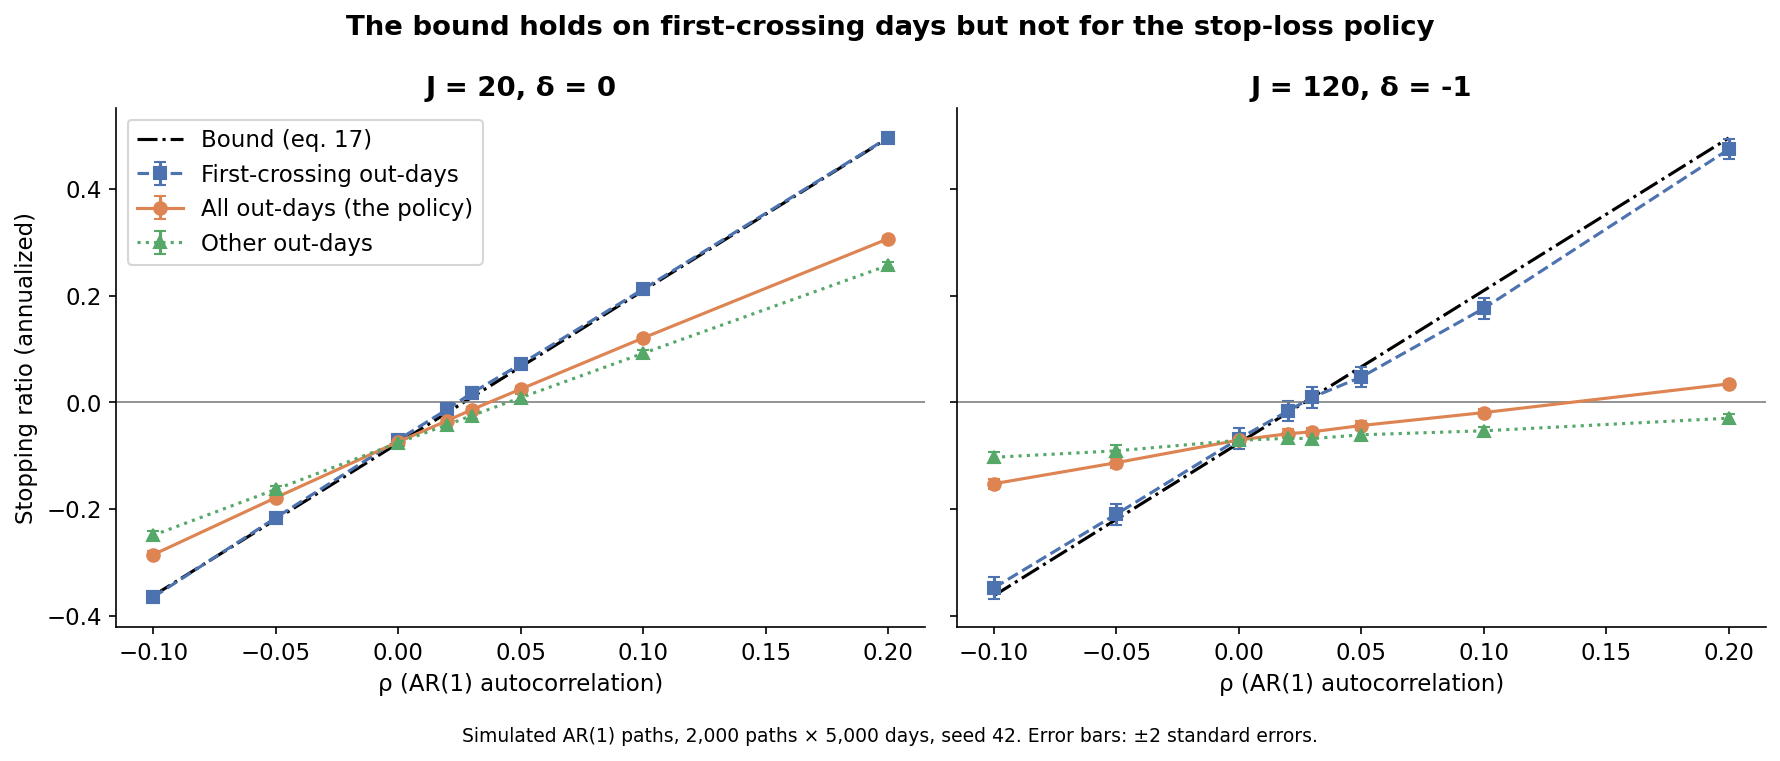

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 150, 'font.size': 11})

panels = [(20, 0.0), (120, -1.0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
d = prop2[prop2.seed == SEEDS[0]]
for ax, (J, delta) in zip(axes, panels):
    s = d[(d.J == J) & (d.delta == delta)].sort_values('rho')
    ax.plot(s.rho, s.bound, color='black', linestyle='-.', linewidth=1.5, label='Bound (eq. 17)')
    ax.errorbar(s.rho, s.ratio_first, yerr=2 * s.se_first, color='#4C72B0', linestyle='--',
                marker='s', capsize=3, label='First-crossing out-days')
    ax.errorbar(s.rho, s.stopping_ratio, yerr=2 * s.se, color='#DD8452', linestyle='-',
                marker='o', capsize=3, label='All out-days (the policy)')
    ax.errorbar(s.rho, s.ratio_other, yerr=2 * s.se_other, color='#55A868', linestyle=':',
                marker='^', capsize=3, label='Other out-days')
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.set_title(f'J = {J}, δ = {delta:g}', fontweight='bold')
    ax.set_xlabel('ρ (AR(1) autocorrelation)')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
axes[0].set_ylabel('Stopping ratio (annualized)')
axes[0].legend(loc='upper left', frameon=True)
fig.suptitle('The bound holds on first-crossing days but not for the stop-loss policy', fontweight='bold')
fig.text(0.5, -0.03, f'Simulated AR(1) paths, {N_PATHS:,} paths × {N_STEPS:,} days, seed {SEEDS[0]}. '
         'Error bars: ±2 standard errors.', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT}/fig_prop2_bound_split.png', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUT}/fig_prop2_bound_split.pdf', bbox_inches='tight')
plt.show()